In [1]:

import sys
import pandas as pd
import matplotlib.pyplot as plt

print("Jupyter Notebook is working!")
print("Python:", sys.executable)

data = pd.read_csv(
    r"D:\Research\Reading_Fluency\pipeline\features.csv"
)

print("Dataset shape:", data.shape)
display(data.head())


Jupyter Notebook is working!
Python: d:\Research\Literacy-Screening\Literacy-Screening-j26it382\backend\.venv\Scripts\python.exe
Dataset shape: (131, 19)


,Audio_File,Student_ID,Passage_ID,ref_words,window_words,extra_words,wpm,wcpm,accuracy,skip_rate,sub_rate,ins_rate,pause_count,avg_pause,total_pause,long_pauses,duration,Teacher_Score,Teacher_Label
0,S001_G4_P1_S2.wav,S001,P1,77,67,2,125.860989,108.954289,0.753247,0.155844,0.090909,0.025974,10,0.488000,4.88,0,31.94,8.0,High
1,S001_G5_P1_S2.wav,S001,P1,77,67,0,51.710831,39.361976,0.662338,0.142857,0.194805,0.012987,9,1.228889,11.06,4,77.74,6.0,Medium
2,S002_G4_P1_S2.wav,S002,P1,77,68,0,118.881119,108.391608,0.805195,0.129870,0.064935,0.012987,8,0.635000,5.08,0,34.32,7.0,Medium
3,S002_G5_P1_S2.wav,S002,P1,77,63,0,86.538462,86.538462,0.818182,0.181818,0.000000,0.000000,8,0.760000,6.08,1,43.68,6.0,Medium
4,S002_G5_P1_S2_2.wav,S002,P1,77,66,0,141.428571,139.285714,0.844156,0.142857,0.012987,0.000000,10,0.568000,5.68,1,28.00,9.0,High


In [4]:

# Cell 2 - Dataset Analysis

ORDER = ["Low", "Medium", "High"]

FEATURES = [
    "wpm", "wcpm", "accuracy",
    "skip_rate", "sub_rate", "ins_rate",
    "pause_count", "avg_pause",
    "total_pause", "long_pauses", "duration"
]

# Keep only recordings with valid teacher labels
df = data[data["Teacher_Label"].isin(ORDER)].copy()

print("=== DATASET INFORMATION ===")
print("Total recordings:", len(df))
print("Unique students:", df["Student_ID"].nunique())
print("Number of features:", len(FEATURES))

print("\n=== TEACHER LABEL DISTRIBUTION ===")
display(df["Teacher_Label"].value_counts().reindex(ORDER))

print("\n=== MISSING VALUES ===")
display(df[FEATURES + ["Student_ID", "Teacher_Label"]].isnull().sum())

print("\n=== FEATURE STATISTICS ===")
display(df[FEATURES].describe().round(2))


=== DATASET INFORMATION ===
Total recordings: 130
Unique students: 65
Number of features: 11

=== TEACHER LABEL DISTRIBUTION ===


Teacher_Label
Low       26
Medium    52
High      52
Name: count, dtype: int64


=== MISSING VALUES ===


wpm              0
wcpm             0
accuracy         0
skip_rate        0
sub_rate         0
ins_rate         0
pause_count      0
avg_pause        0
total_pause      0
long_pauses      0
duration         0
Student_ID       0
Teacher_Label    0
dtype: int64


=== FEATURE STATISTICS ===


,wpm,wcpm,accuracy,skip_rate,sub_rate,ins_rate,pause_count,avg_pause,total_pause,long_pauses,duration
count,130.00,130.00,130.00,130.00,130.00,130.00,130.00,130.00,130.00,130.00,130.00
mean,85.67,75.41,0.60,0.30,0.10,0.01,8.74,2.03,14.45,2.23,46.19
std,39.33,43.81,0.29,0.26,0.12,0.02,3.35,3.98,19.54,2.74,28.32
min,7.76,3.10,0.03,0.06,0.00,0.00,0.00,0.00,0.00,0.00,1.76
25%,53.83,38.62,0.44,0.14,0.01,0.00,8.00,0.60,5.38,0.00,30.04
50%,88.43,76.47,0.76,0.17,0.05,0.00,10.00,0.79,7.59,2.00,40.51
75%,109.64,103.05,0.82,0.35,0.13,0.01,10.75,1.49,11.98,3.00,50.76
max,191.18,179.41,0.86,0.97,0.51,0.14,17.00,35.06,117.86,14.00,158.46


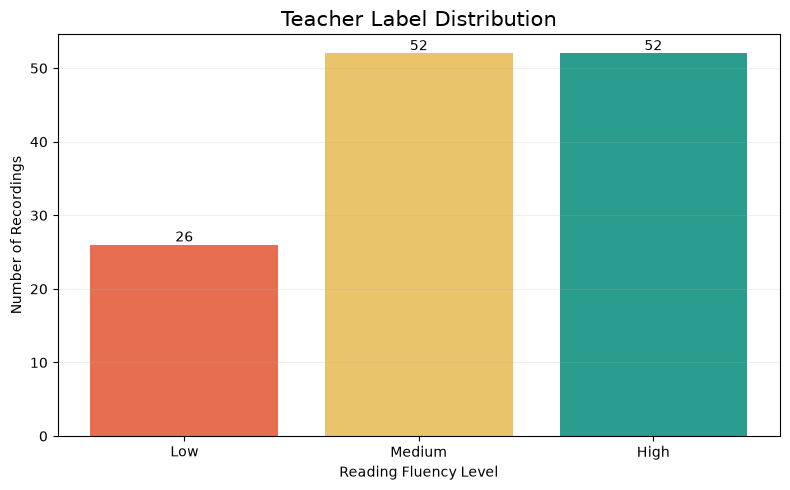

In [5]:

# Cell 3 - Teacher Label Distribution Chart

import matplotlib.pyplot as plt

label_counts = df["Teacher_Label"].value_counts().reindex(ORDER)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    label_counts.index,
    label_counts.values,
    color=["#e76f51", "#e9c46a", "#2a9d8f"]
)

plt.title("Teacher Label Distribution", fontsize=15)
plt.xlabel("Reading Fluency Level")
plt.ylabel("Number of Recordings")

plt.bar_label(bars)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


In [6]:

# Cell 4 - Prepare data for ML training

import numpy as np
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

X = df[FEATURES].values

label_mapping = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

y = df["Teacher_Label"].map(label_mapping).values
groups = df["Student_ID"].values

assert df[FEATURES].notna().all().all(), "Missing feature values found"
assert df["Student_ID"].notna().all(), "Missing Student_ID found"
assert len(np.unique(y)) == 3, "Expected three classes"

print("ML data prepared successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique students:", len(np.unique(groups)))
print("Class mapping:", label_mapping)


ML data prepared successfully!
X shape: (130, 11)
y shape: (130,)
Unique students: 65
Class mapping: {'Low': 0, 'Medium': 1, 'High': 2}


In [7]:

# Cell 5 - Initialize ML models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        random_state=42
    )
}

print("Models initialized:")
for name in models:
    print("-", name)


Models initialized:
- Logistic Regression
- Random Forest
- XGBoost


In [10]:

# Cell 5A - Demonstrate Training and Validation Separately

from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Split the data using student groups
train_idx, val_idx = next(cv.split(X, y, groups))

X_train = X[train_idx]
X_val = X[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

print("=== DATA SPLITTING ===")
print("Training recordings:", len(X_train))
print("Validation recordings:", len(X_val))

# Create a separate model for demonstration
model = clone(models["Logistic Regression"])

# STEP 1 - TRAINING
model.fit(X_train, y_train)
print("\nModel training completed!")

# STEP 2 - VALIDATION
y_pred = model.predict(X_val)
print("Validation predictions completed!")

# STEP 3 - EVALUATION
accuracy = accuracy_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred, average="macro")

print("\n=== VALIDATION RESULTS ===")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Macro F1-score: {f1:.3f}")


=== DATA SPLITTING ===
Training recordings: 104
Validation recordings: 26

Model training completed!
Validation predictions completed!

=== VALIDATION RESULTS ===
Accuracy: 61.54%
Macro F1-score: 0.634


=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

         Low       0.62      1.00      0.77         5
      Medium       0.56      0.45      0.50        11
        High       0.67      0.60      0.63        10

    accuracy                           0.62        26
   macro avg       0.62      0.68      0.63        26
weighted avg       0.61      0.62      0.60        26

=== CONFUSION MATRIX ===


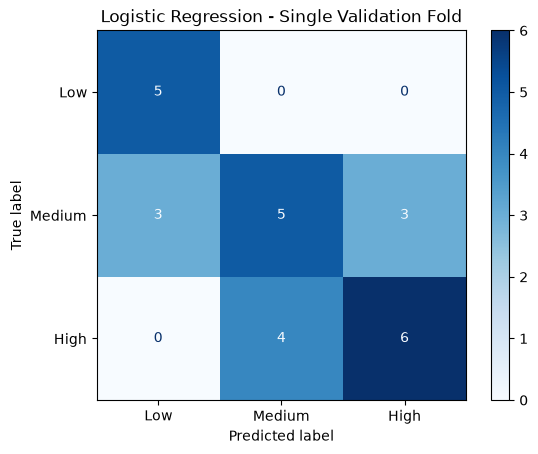

In [13]:

from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("=== CLASSIFICATION REPORT ===")

print(classification_report(
    y_val,
    y_pred,
    labels=[0, 1, 2],
    target_names=["Low", "Medium", "High"],
    zero_division=0
))

print("=== CONFUSION MATRIX ===")

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    labels=[0, 1, 2],
    display_labels=["Low", "Medium", "High"],
    cmap="Blues"
)

plt.title("Logistic Regression - Single Validation Fold")
plt.show()


In [15]:

# Cell 6 - Train and evaluate models using grouped CV

from sklearn.model_selection import cross_val_predict

results = []
confusion_matrices = {}

for name, model in models.items():

    accuracies = []
    f1_scores = []

    print(f"\nEvaluating {name}...")

    for seed in range(5):
        cv = StratifiedGroupKFold(
            n_splits=5,
            shuffle=True,
            random_state=seed
        )

        predictions = cross_val_predict(
            model,
            X,
            y,
            cv=cv,
            groups=groups
        )

        acc = accuracy_score(y, predictions)
        f1 = f1_score(y, predictions, average="macro")

        accuracies.append(acc)
        f1_scores.append(f1)

        print(
            f"Seed {seed}: "
            f"Accuracy={acc:.3f}, "
            f"Macro-F1={f1:.3f}"
        )

        if seed == 0:
            confusion_matrices[name] = confusion_matrix(
                y, predictions, labels=[0, 1, 2]
            )

    results.append({
        "Model": name,
        "Accuracy": np.mean(accuracies),
        "Macro_F1": np.mean(f1_scores),
        "Accuracy_SD": np.std(accuracies),
        "F1_SD": np.std(f1_scores)
    })

results_df = pd.DataFrame(results)

print("\n=== FINAL MODEL COMPARISON ===")
display(results_df.round(4))



Evaluating Logistic Regression...
Seed 0: Accuracy=0.654, Macro-F1=0.661
Seed 1: Accuracy=0.646, Macro-F1=0.658
Seed 2: Accuracy=0.600, Macro-F1=0.607
Seed 3: Accuracy=0.631, Macro-F1=0.643
Seed 4: Accuracy=0.646, Macro-F1=0.653

Evaluating Random Forest...
Seed 0: Accuracy=0.600, Macro-F1=0.610
Seed 1: Accuracy=0.631, Macro-F1=0.643
Seed 2: Accuracy=0.615, Macro-F1=0.629
Seed 3: Accuracy=0.623, Macro-F1=0.634
Seed 4: Accuracy=0.631, Macro-F1=0.641

Evaluating XGBoost...
Seed 0: Accuracy=0.600, Macro-F1=0.601
Seed 1: Accuracy=0.608, Macro-F1=0.610
Seed 2: Accuracy=0.592, Macro-F1=0.594
Seed 3: Accuracy=0.577, Macro-F1=0.571
Seed 4: Accuracy=0.600, Macro-F1=0.601

=== FINAL MODEL COMPARISON ===


,Model,Accuracy,Macro_F1,Accuracy_SD,F1_SD
0,Logistic Regression,0.6354,0.6443,0.0192,0.0196
1,Random Forest,0.6200,0.6316,0.0115,0.0118
2,XGBoost,0.5954,0.5953,0.0104,0.0132


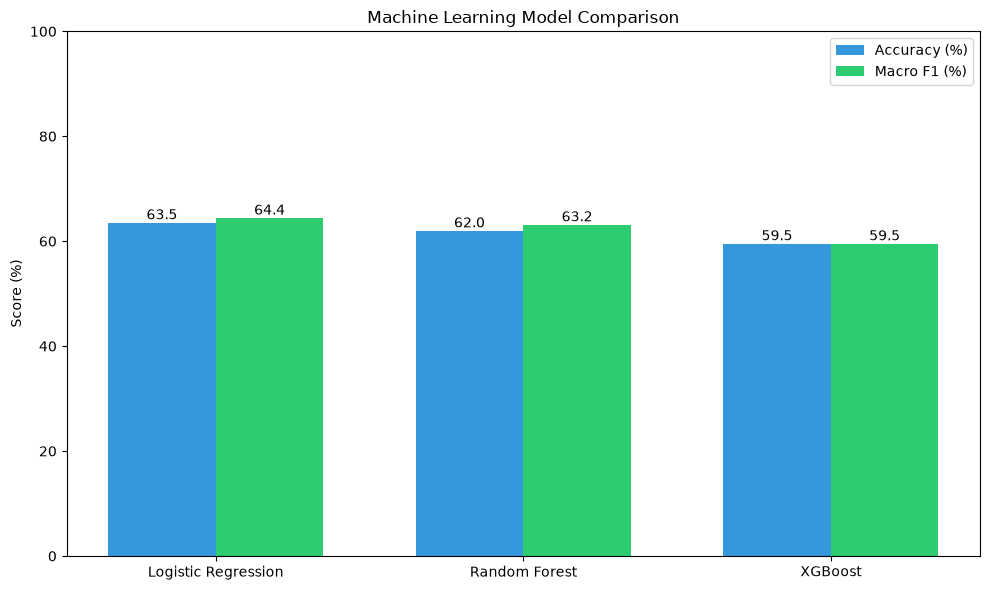

Best model: Logistic Regression
Accuracy: 63.54%
Macro F1: 0.644


In [16]:

# Cell 7 - Model Comparison Chart

import matplotlib.pyplot as plt

x = np.arange(len(results_df))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    results_df["Accuracy"] * 100,
    width,
    label="Accuracy (%)",
    color="#3498db"
)

bars2 = ax.bar(
    x + width / 2,
    results_df["Macro_F1"] * 100,
    width,
    label="Macro F1 (%)",
    color="#2ecc71"
)

ax.set_xticks(x)
ax.set_xticklabels(results_df["Model"])
ax.set_ylabel("Score (%)")
ax.set_title("Machine Learning Model Comparison")
ax.set_ylim(0, 100)
ax.legend()

ax.bar_label(bars1, fmt="%.1f")
ax.bar_label(bars2, fmt="%.1f")

plt.tight_layout()
plt.show()

best_row = results_df.loc[results_df["Macro_F1"].idxmax()]
best_model = best_row["Model"]

print("Best model:", best_model)
print(f"Accuracy: {best_row['Accuracy'] * 100:.2f}%")
print(f"Macro F1: {best_row['Macro_F1']:.3f}")


## RFCS Weight Sensitivity Analysis

Valid recordings: 130


,Combination,Accuracy_W,Speed_W,Completion_W,Pause_W,Spearman_Rho,P_Value
4,Completion-focused,0.30,0.25,0.30,0.15,0.6717,0.0
0,Current,0.35,0.30,0.20,0.15,0.6715,0.0
2,Accuracy-focused,0.40,0.30,0.20,0.10,0.6706,0.0
3,Speed-focused,0.25,0.40,0.20,0.15,0.6693,0.0
1,Equal,0.25,0.25,0.25,0.25,0.6680,0.0


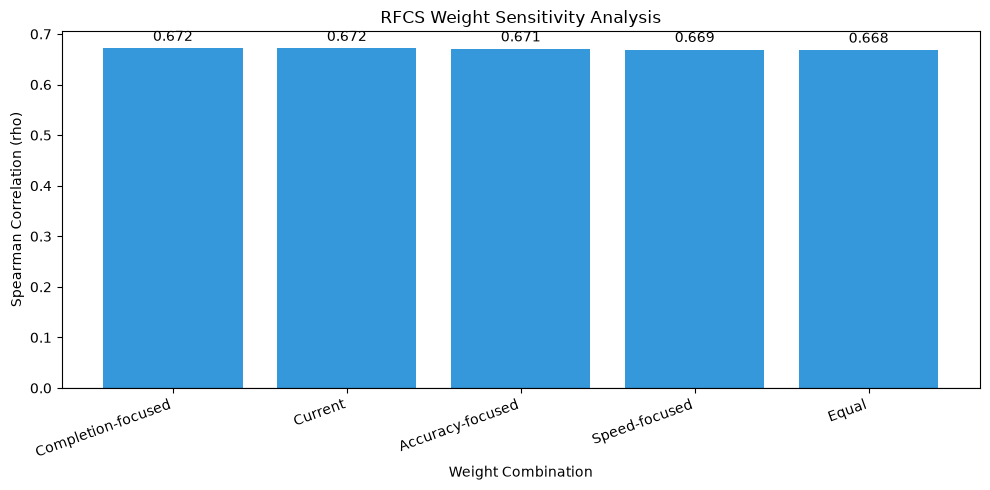


Highest observed correlation:
Completion-focused
Spearman rho: 0.6717


In [17]:

# RFCS Weight Sensitivity Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Use the dataset loaded in Cell 1
rfcs_df = data.copy()

required = [
    "accuracy", "wcpm", "skip_rate",
    "avg_pause", "Teacher_Score"
]

for col in required:
    rfcs_df[col] = pd.to_numeric(
        rfcs_df[col], errors="coerce"
    )

rfcs_df = rfcs_df.dropna(subset=required).copy()

print("Valid recordings:", len(rfcs_df))

# Same normalization as original train_models.py
A = rfcs_df["accuracy"].clip(0, 1)
S = (rfcs_df["wcpm"] / 110).clip(0, 1)
C = (1 - rfcs_df["skip_rate"]).clip(0, 1)
P = (1 - rfcs_df["avg_pause"] / 2).clip(0, 1)

weight_sets = {
    "Current": [0.35, 0.30, 0.20, 0.15],
    "Equal": [0.25, 0.25, 0.25, 0.25],
    "Accuracy-focused": [0.40, 0.30, 0.20, 0.10],
    "Speed-focused": [0.25, 0.40, 0.20, 0.15],
    "Completion-focused": [0.30, 0.25, 0.30, 0.15]
}

results = []

for name, weights in weight_sets.items():
    a, s, c, p = weights

    score = 100 * (a*A + s*S + c*C + p*P)

    rho, p_value = spearmanr(
        score, rfcs_df["Teacher_Score"]
    )

    results.append({
        "Combination": name,
        "Accuracy_W": a,
        "Speed_W": s,
        "Completion_W": c,
        "Pause_W": p,
        "Spearman_Rho": rho,
        "P_Value": p_value
    })

results_df_rfcs = pd.DataFrame(results)
results_df_rfcs = results_df_rfcs.sort_values(
    "Spearman_Rho", ascending=False
)

display(results_df_rfcs.round(4))

# Visual comparison
plt.figure(figsize=(10, 5))

bars = plt.bar(
    results_df_rfcs["Combination"],
    results_df_rfcs["Spearman_Rho"],
    color="#3498db"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Spearman Correlation (rho)")
plt.xlabel("Weight Combination")
plt.title("RFCS Weight Sensitivity Analysis")
plt.xticks(rotation=20, ha="right")
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.tight_layout()
plt.show()

print("\nHighest observed correlation:")
print(results_df_rfcs.iloc[0]["Combination"])
print(
    "Spearman rho:",
    round(results_df_rfcs.iloc[0]["Spearman_Rho"], 4)
)
